In [2]:
import pandas as pd
import numpy as np
import time
from scipy.optimize import minimize, Bounds

# Load input data
data = pd.read_excel('data/input42u.xlsx')
a = data['a'].values
b = data['b'].values
c = data['c'].values
Minimum_Capacity = data['pmin'].values
Maximum_Capacity = data['pmax'].values
ramp_up = data['rampup'].values
ramp_down = data['rampdown'].values
Unit = data['Unit'].values

penalty_factor = 1e6

# Load power demand
power_demand_data = pd.read_excel('data/power_demand42u.xlsx')
power_demand = power_demand_data['load'].values

# Cost function with penalty
def calculate_fuel_cost_with_penalty(P, a, b, c, demand):
    squaredP = np.multiply(P, P)
    Fuel_Cost = np.divide(np.add(a, np.multiply(b, P) + np.multiply(c, squaredP)), 1000)
    power_difference = np.sum(P) - demand
    penalty_term = penalty_factor * abs(power_difference)
    total_Fuel_Cost = np.sum(Fuel_Cost) + penalty_term
    return total_Fuel_Cost

# tc optimization wrapper
def tc(func, initial_guess, bounds):
    result = minimize(
        fun=func,
        x0=initial_guess,
        bounds=bounds,
        method='trust-constr'
    )
    return result.x, result.fun

# Main optimization loop
all_outputs = []
schedulling = []

for load_counter, demand in enumerate(power_demand, start=1):
    start_time = time.time()
    if load_counter == 1:
        previous_output = None
    else:
        previous_output = all_outputs[-1]['Output']['Power Produced (MW)'].values

    initial_guess = (Minimum_Capacity + Maximum_Capacity) / 2
    bounds = list(zip(Minimum_Capacity, Maximum_Capacity))

    def objective(P):
        return calculate_fuel_cost_with_penalty(P, a, b, c, demand)

    P_opt, cost = tc(objective, initial_guess, bounds)

    # Enforce capacity and power balance
    for _ in range(10):
        P_opt = np.minimum(np.maximum(P_opt, Minimum_Capacity), Maximum_Capacity)
        power_difference = np.sum(P_opt) - demand
        if power_difference > 0:
            for j in range(len(P_opt)):
                if P_opt[j] > Minimum_Capacity[j]:
                    reduction = min(P_opt[j] - Minimum_Capacity[j], power_difference)
                    P_opt[j] -= reduction
                    power_difference -= reduction
        elif power_difference < 0:
            for j in range(len(P_opt)):
                if P_opt[j] < Maximum_Capacity[j]:
                    increase = min(Maximum_Capacity[j] - P_opt[j], abs(power_difference))
                    P_opt[j] += increase
                    power_difference += increase

    end_time = time.time()

    output = pd.DataFrame({'Unit': Unit, 'Power Produced (MW)': P_opt})
    print("Load Counter: {}".format(load_counter))
    print(f"Output for Power Demand {demand:.2f} MW")
    print(output)
    print(f"Total Power Produced: {np.sum(P_opt):.2f} MW")
    print(f'Total Fuel Cost: Rp {cost}')
    print(f'Computation Time: {end_time - start_time} seconds')
    print('------------------------------------------------\n')

    all_outputs.append({
        'Demand': demand,
        'Output': output,
        'Total Power Produced': np.sum(P_opt),
        'Total Fuel Cost': cost,
        'Computation Time': end_time - start_time
    })

    output_info = {'Demand': demand}
    for unit_index, unit in enumerate(Unit):
        output_info[f'Unit {unit} Power Produced'] = P_opt[unit_index]
        output_info[f'Unit {unit} Cost'] = cost
    schedulling.append(output_info)

# Ramp rate and generation limit check
ramp_rates = []
generation_limits = []
for i in range(1, len(power_demand)):
    prev = all_outputs[i - 1]['Output']['Power Produced (MW)'].values
    curr = all_outputs[i]['Output']['Power Produced (MW)'].values
    ramp_rate = curr - prev
    violations = np.logical_or(ramp_rate > ramp_up, ramp_rate < -ramp_down)

    ramp_rate_info = {'Demand': power_demand[i]}
    generation_limit_info = {'Demand': power_demand[i]}
    for unit_index, unit in enumerate(Unit):
        ramp_rate_info[f'Unit {unit}'] = ramp_rate[unit_index]
        ramp_rate_info[f'Unit {unit} Violation'] = violations[unit_index]
        gen_violation = (curr[unit_index] < Minimum_Capacity[unit_index]) or (curr[unit_index] > Maximum_Capacity[unit_index])
        generation_limit_info[f'Unit {unit}'] = curr[unit_index]
        generation_limit_info[f'Unit {unit} Violation'] = gen_violation
    ramp_rates.append(ramp_rate_info)
    generation_limits.append(generation_limit_info)

# Save to Excel
output_file_path = 'trust-constr (ED).xlsx'
with pd.ExcelWriter(output_file_path) as writer:
    pd.DataFrame(schedulling).to_excel(writer, sheet_name='Schedulling', index=False)
    pd.DataFrame(all_outputs).to_excel(writer, sheet_name='Summary', index=False)
    pd.DataFrame(ramp_rates).to_excel(writer, sheet_name='Ramp Rates', index=False)
    pd.DataFrame(generation_limits).to_excel(writer, sheet_name='Generation Limits', index=False)

print("All results saved to 'trust-constr (ED).xlsx'")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_differentiable_functions.py:316: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


Load Counter: 1
Output for Power Demand 8761.42 MW
    Unit  Power Produced (MW)
0      1           302.925240
1      2           302.924361
2      3           302.924417
3      4           302.925225
4      5           409.581393
5      6           409.582360
6      7           409.582870
7      8           174.599450
8      9           174.599453
9     10           174.599453
10    11           174.596422
11    12            40.001562
12    13            79.977438
13    14           169.982314
14    15           169.994673
15    16           285.073903
16    17           264.921214
17    18           264.920116
18    19             5.000025
19    20             5.000025
20    21            60.001235
21    22            60.001590
22    23            60.001516
23    24            60.001487
24    25            60.001436
25    26            60.001437
26    27            60.001456
27    28            60.001532
28    29           400.014175
29    30           400.014175
30    31           

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_differentiable_functions.py:316: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


Load Counter: 3
Output for Power Demand 8613.11 MW
    Unit  Power Produced (MW)
0      1           250.000126
1      2           250.000041
2      3           250.000000
3      4           250.000000
4      5           408.000001
5      6           408.000001
6      7           408.000001
7      8           174.599998
8      9           174.599998
9     10           174.599996
10    11           174.599999
11    12            79.999903
12    13            79.999996
13    14            83.096588
14    15            82.610915
15    16           220.000035
16    17           220.000050
17    18           220.000010
18    19            15.999947
19    20            15.999946
20    21           118.499994
21    22           118.499994
22    23           118.499994
23    24           118.499994
24    25           118.499994
25    26           118.499994
26    27           118.499994
27    28           118.499994
28    29           400.000001
29    30           400.000001
30    31           

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_differentiable_functions.py:316: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


Load Counter: 4
Output for Power Demand 8573.30 MW
    Unit  Power Produced (MW)
0      1           250.000000
1      2           250.000000
2      3           250.000000
3      4           250.000000
4      5           408.000000
5      6           408.000000
6      7           408.000000
7      8           174.576362
8      9           174.598934
9     10           174.599396
10    11           174.600000
11    12            79.999996
12    13            55.923724
13    14            75.000000
14    15            75.000000
15    16           220.000000
16    17           220.000000
17    18           220.000000
18    19            15.998799
19    20            15.998790
20    21           118.500000
21    22           118.500000
22    23           118.500000
23    24           118.500000
24    25           118.500000
25    26           118.500000
26    27           118.500000
27    28           118.500000
28    29           400.000000
29    30           400.000000
30    31           

... (20 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_differentiable_functions.py:316: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


Load Counter: 22
Output for Power Demand 10411.10 MW
    Unit  Power Produced (MW)
0      1           371.499971
1      2           371.499971
2      3           371.499971
3      4           371.499971
4      5           466.793790
5      6           466.793683
6      7           466.791798
7      8           174.599743
8      9           174.599743
9     10           174.599743
10    11           174.599743
11    12            79.999741
12    13            79.999741
13    14           169.999588
14    15           169.999587
15    16           378.654842
16    17           378.651246
17    18           378.651990
18    19            15.999768
19    20            15.999768
20    21           118.499787
21    22           118.499787
22    23           118.499787
23    24           118.499787
24    25           118.499787
25    26           118.499787
26    27           118.499787
27    28           118.499787
28    29           400.009993
29    30           400.010000
30    31         

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_differentiable_functions.py:316: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


Load Counter: 23
Output for Power Demand 10340.36 MW
    Unit  Power Produced (MW)
0      1           371.499980
1      2           371.499977
2      3           371.499977
3      4           371.499977
4      5           463.710643
5      6           460.449595
6      7           459.439710
7      8           174.599994
8      9           174.599994
9     10           174.599994
10    11           174.599994
11    12            79.999993
12    13            79.999993
13    14           169.999998
14    15           169.999993
15    16           346.252890
16    17           368.668628
17    18           368.511882
18    19            15.999992
19    20            15.999992
20    21           118.499994
21    22           118.499994
22    23           118.499994
23    24           118.499994
24    25           118.499994
25    26           118.499994
26    27           118.499994
27    28           118.499994
28    29           400.007327
29    30           400.011946
30    31         

Running F01 (dim=30)...


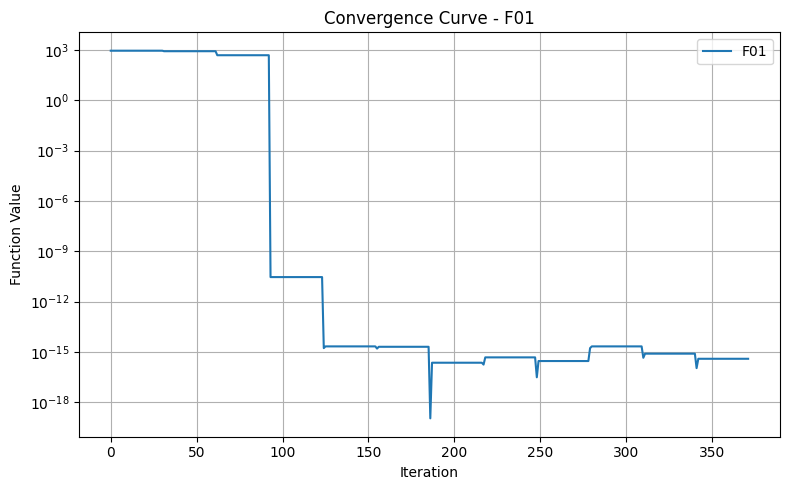

Running F02 (dim=30)...


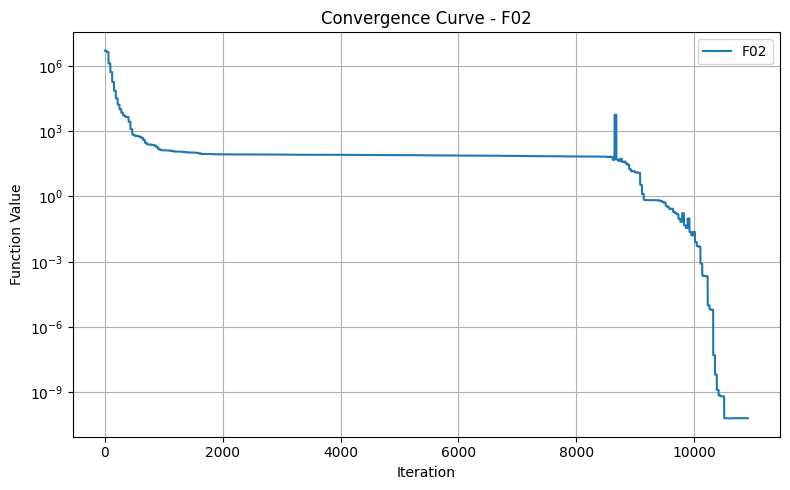

Running F03 (dim=30)...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_differentiable_functions.py:316: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


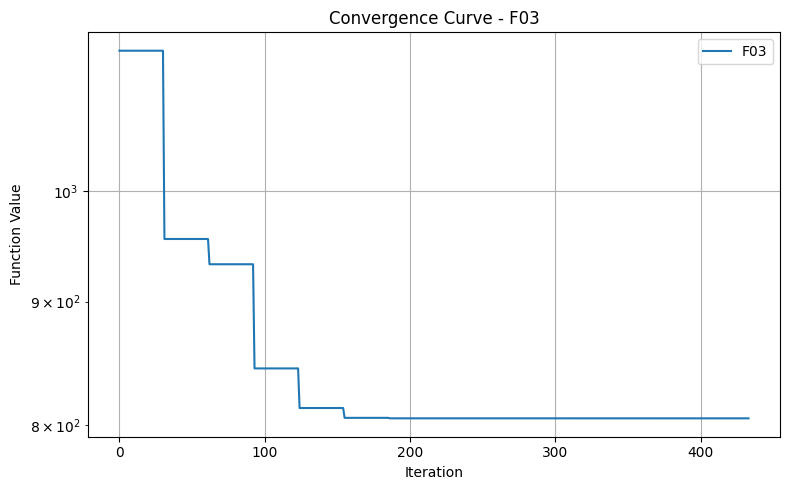

Running F04 (dim=30)...


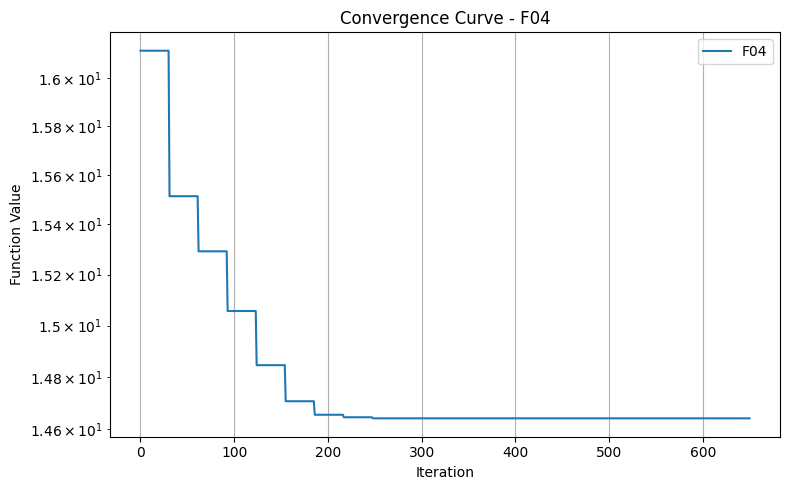

Running F05 (dim=30)...


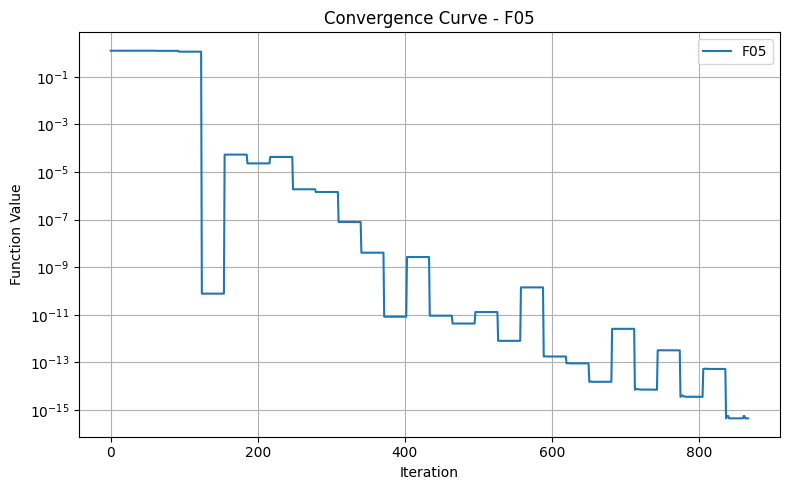

Running F06 (dim=30)...


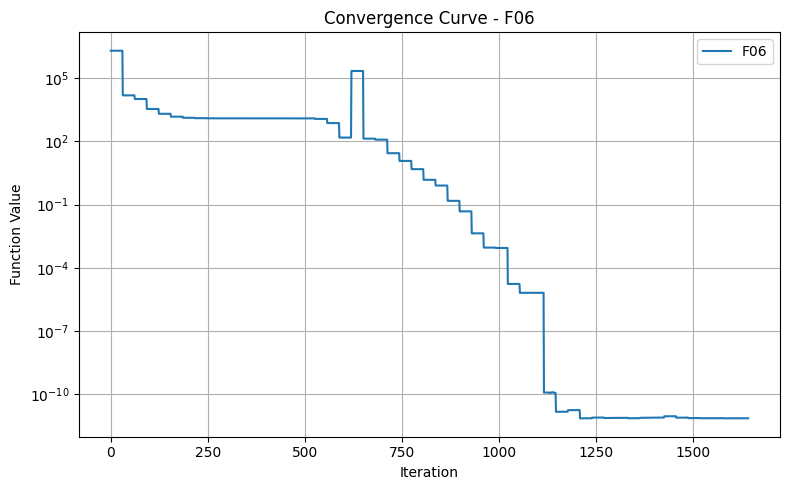

Running F07 (dim=30)...


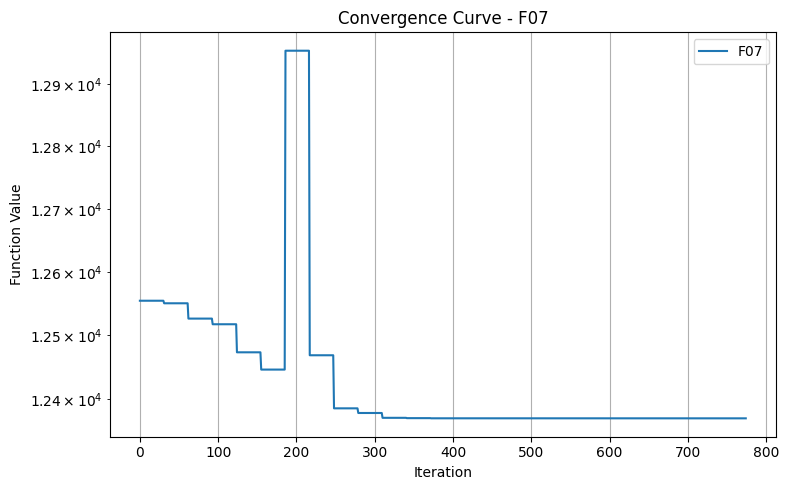

Running F08 (dim=30)...


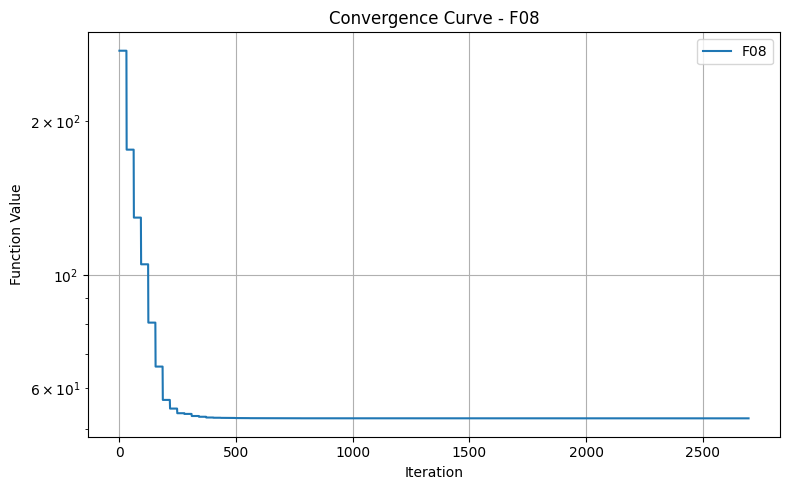

Running F09 (dim=30)...


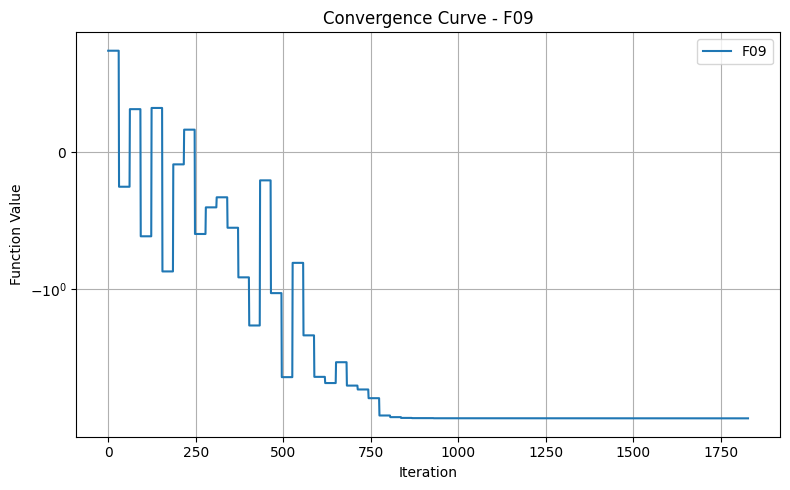

Running F10 (dim=30)...


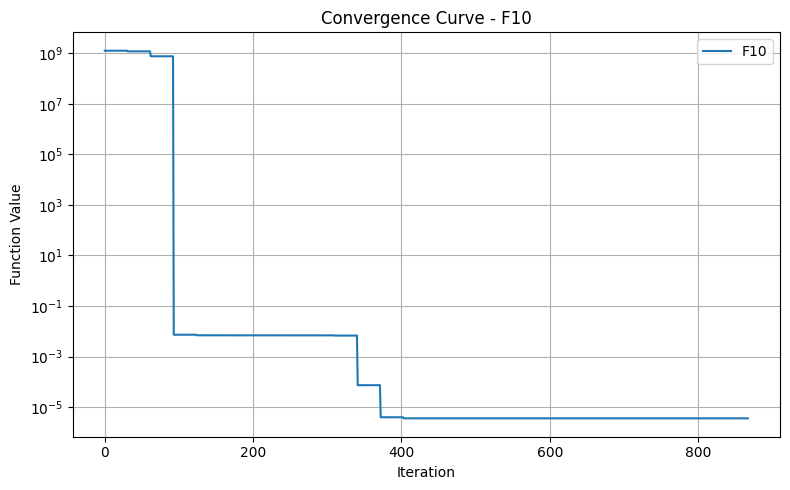

Running F11 (dim=30)...


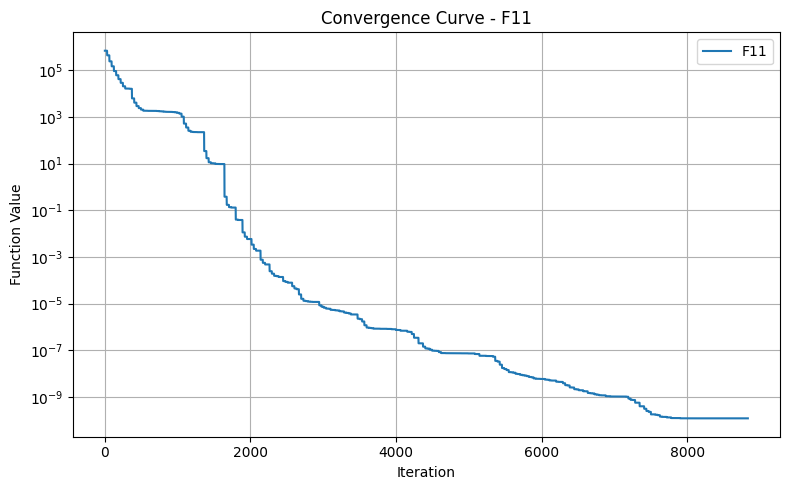

Running F12 (dim=30)...


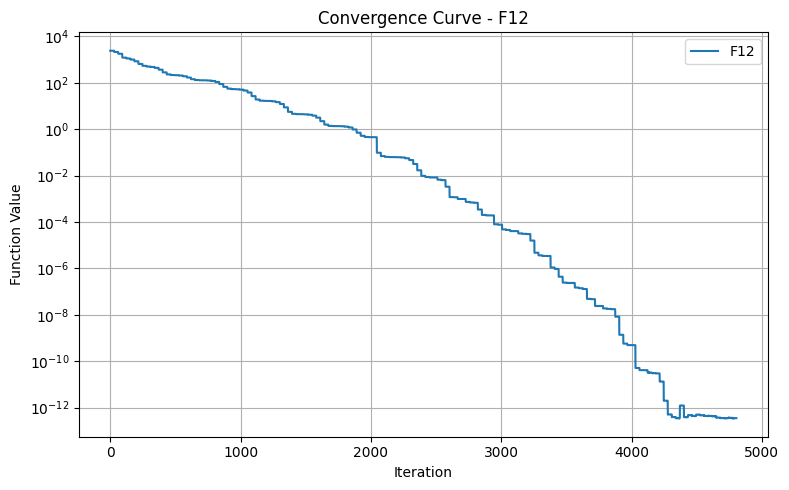

Running F13 (dim=30)...


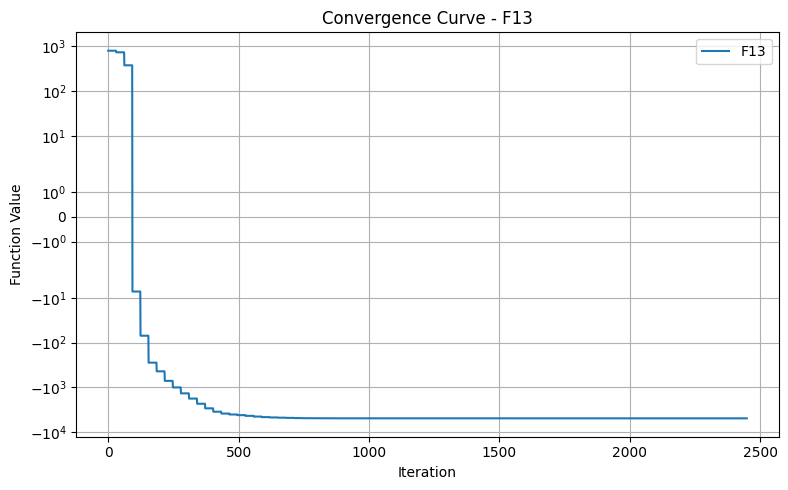

Running F14 (dim=30)...


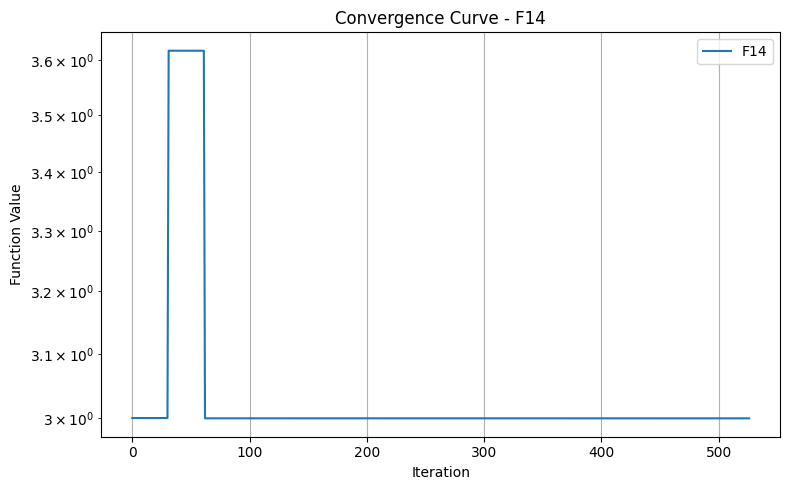

Running F15 (dim=30)...


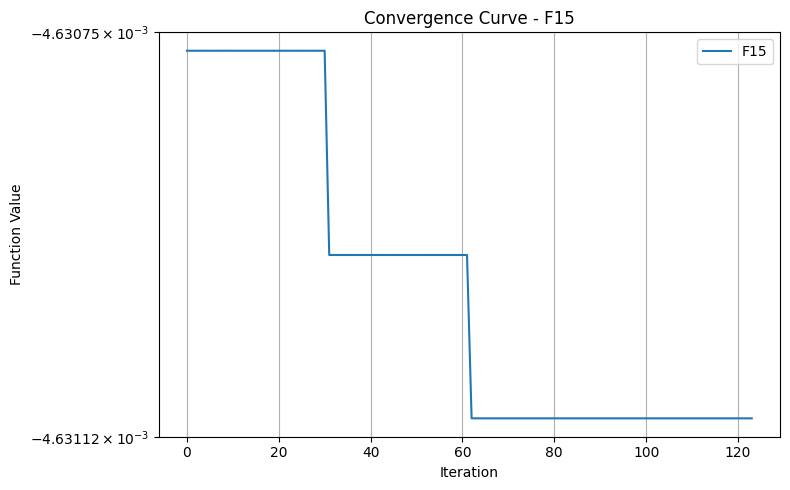

Running F16 (dim=2)...


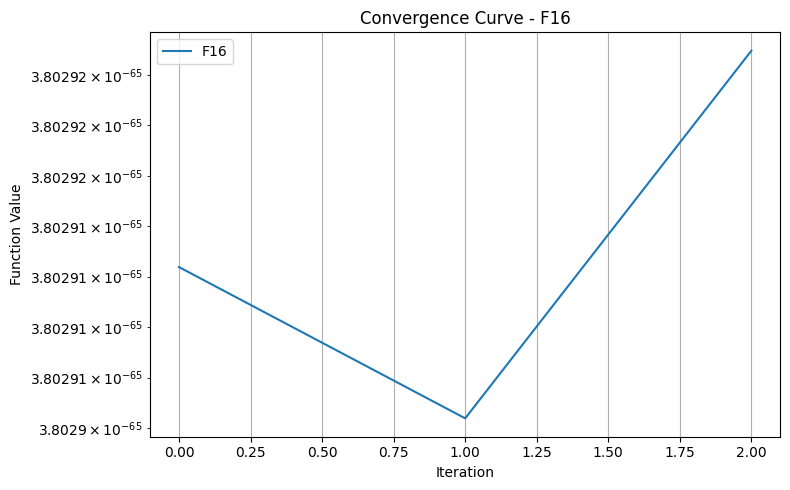

Running F17 (dim=2)...


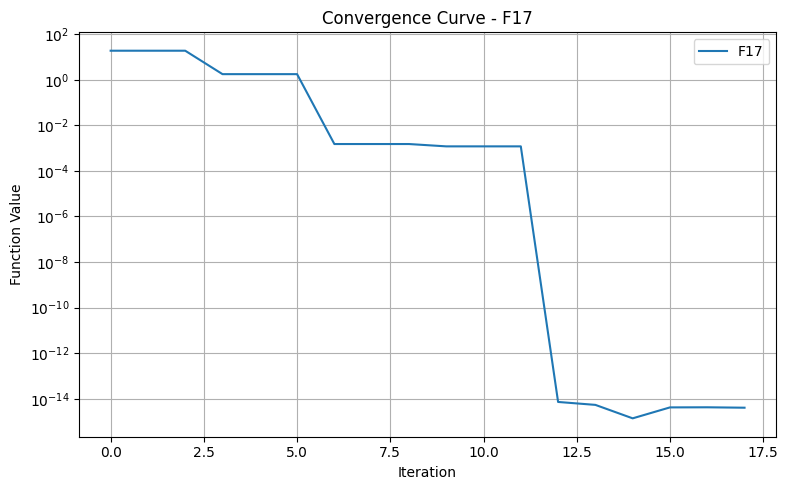

Running F18 (dim=2)...


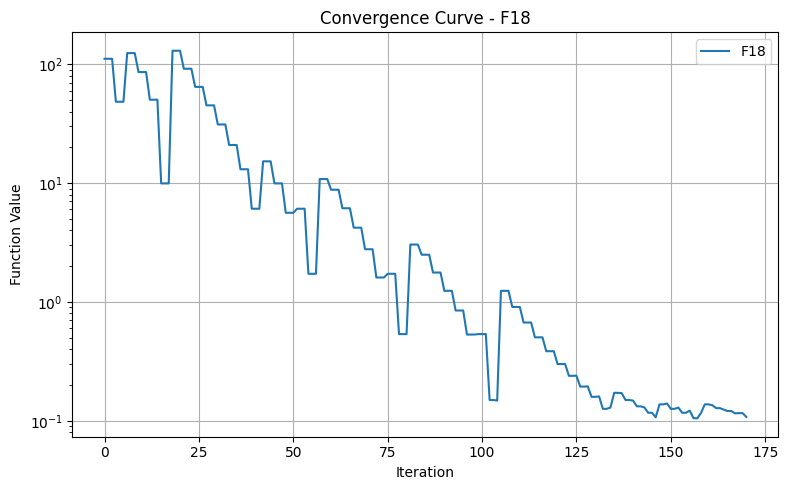

Running F19 (dim=2)...


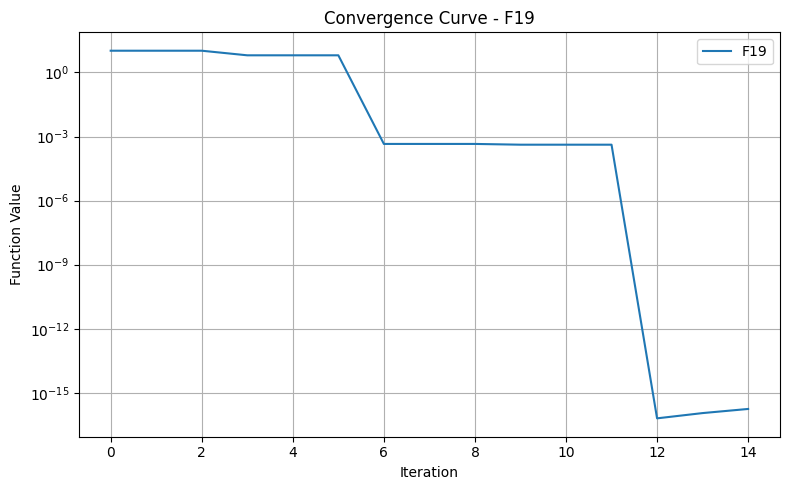

Running F20 (dim=2)...


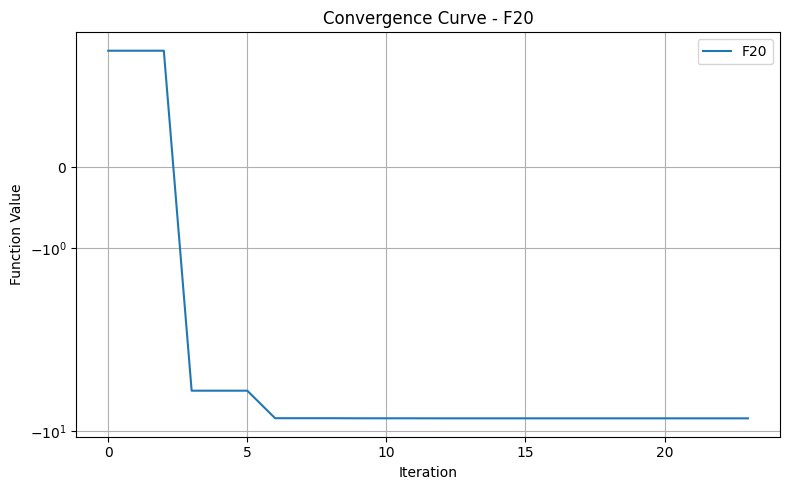

Running F21 (dim=2)...


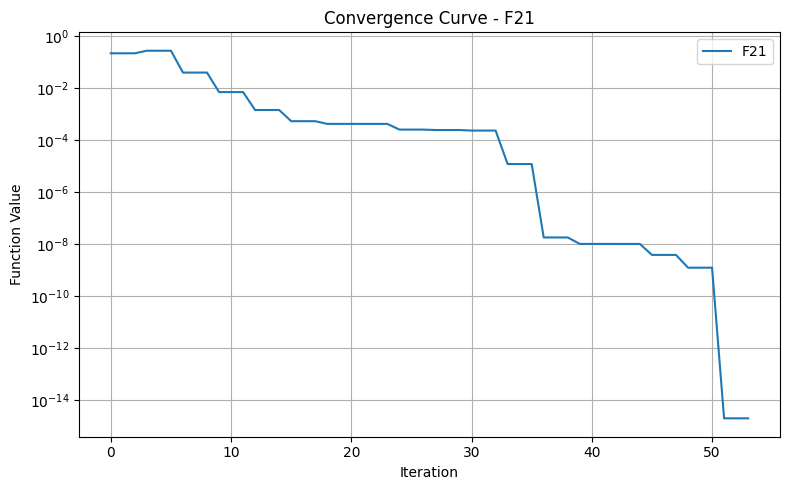

Running F22 (dim=2)...


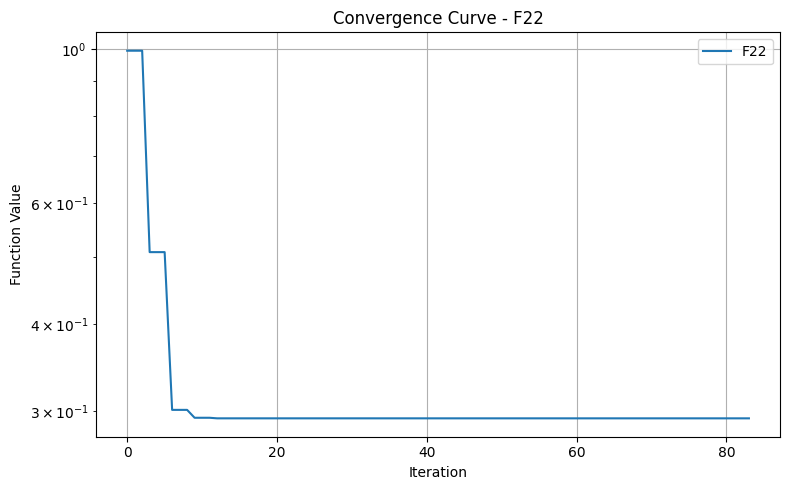

Running F23 (dim=2)...


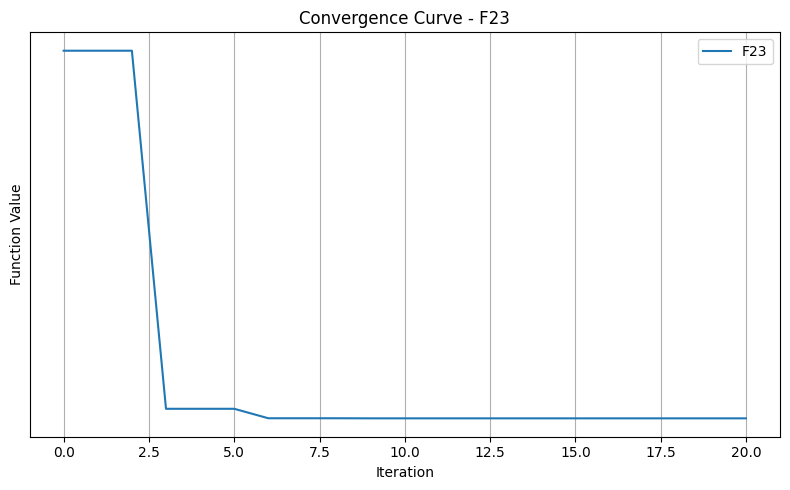


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       1.542071e-20  1.266020e-19  8.213793e-20  5.311995e-19  1.315408e-19
F02       5.833122e-12  1.328875e-01  6.342932e-11  3.986624e+00  7.156209e-01
F03       7.243134e+02  9.838233e+02  9.810028e+02  1.358080e+03  1.555408e+02
F04       1.182282e+01  1.370920e+01  1.384210e+01  1.464166e+01  6.244340e-01
F05       1.110223e-16  7.623531e-16  6.661338e-16  1.776357e-15  3.853752e-16
F06       1.709838e-13  8.462220e-09  1.423157e-10  1.261799e-07  2.551426e-08
F07       1.220948e+04  1.231690e+04  1.232023e+04  1.245113e+04  5.229136e+01
F08       2.893534e+01  5.330023e+01  5.177354e+01  7.766850e+01  1.093211e+01
F09      -9.980399e+00 -5.706086e+00 -6.055993e+00 -6.417205e-01  2.322398e+00
F10       2.913880e-14  5.264266e-07  2.049584e-11  3.573644e-06  9.247035e-07
F11       7.182659e-12  5

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Benchmark Functions (F1–F23) ---
def F1(x): return np.sum(x**2)
def F2(x): return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (x[:-1] - 1)**2)
def F3(x): return np.sum(x**2 - 10 * np.cos(2 * np.pi * x) + 10)
def F4(x): return -20 * np.exp(-0.2*np.sqrt(np.mean(x**2))) - np.exp(np.mean(np.cos(2*np.pi*x))) + 20 + np.e
def F5(x): return np.sum(x**2)/4000 - np.prod(np.cos(x / np.sqrt(np.arange(1, len(x)+1)))) + 1
def F6(x): return np.sum(x**2) + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**2 + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**4
def F7(x): return 418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x))))
def F8(x): 
    w = 1 + (x - 1) / 4
    return np.sin(np.pi * w[0])**2 + np.sum((w[:-1] - 1)**2 * (1 + 10*np.sin(np.pi*w[:-1] + 1)**2)) + (w[-1]-1)**2 * (1 + np.sin(2*np.pi*w[-1])**2)
def F9(x): return -np.sum(np.sin(x) * np.sin(((np.arange(1, len(x)+1) * x**2) / np.pi))**20)
def F10(x): return x[0]**2 + 1e6 * np.sum(x[1:]**2)
def F11(x): return np.sum(np.abs(x)**(2 + 4*np.arange(len(x))/(len(x)-1)))
def F12(x): return np.sum([np.sum(x[:i])**2 for i in range(1, len(x)+1)])
def F13(x): return np.sum((x - 1)**2) - np.sum(x[:-1] * x[1:])
def F14(x): return 1 - np.cos(2*np.pi*np.sqrt(np.sum(x**2))) + 0.1*np.sqrt(np.sum(x**2))
def F15(x): return - (1 + np.cos(12*np.sqrt(np.sum(x**2)))) / (0.5*np.sum(x**2) + 2)
def F16(x): return -np.cos(x[0]) * np.cos(x[1]) * np.exp(-(x[0]-np.pi)**2 - (x[1]-np.pi)**2)
def F17(x): return (x[0] + 2*x[1] - 7)**2 + (2*x[0] + x[1] - 5)**2
def F18(x): return 100*np.sqrt(abs(x[1] - 0.01*x[0]**2)) + 0.01*abs(x[0] + 10)
def F19(x): return 0.26*(x[0]**2 + x[1]**2) - 0.48*x[0]*x[1]
def F20(x): return np.sin(x[0]+x[1]) + (x[0]-x[1])**2 - 1.5*x[0] + 2.5*x[1] + 1
def F21(x): return 0.5 + (np.sin(x[0]**2 - x[1]**2)**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F22(x): return 0.5 + (np.cos(np.sin(abs(x[0]**2 - x[1]**2)))**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F23(x): 
    r = np.sqrt(x[0]**2 + x[1]**2)
    z = np.clip(abs(1 - r / np.pi), -50, 50)
    try:
        exp_term = np.exp(z)
    except:
        exp_term = 1e10
    return -abs(np.sin(x[0]) * np.cos(x[1]) * exp_term)

benchmark_functions = {
    f"F{str(i+1).zfill(2)}": f for i, f in enumerate([
        F1, F2, F3, F4, F5, F6, F7, F8, F9, F10, F11, F12, F13, F14, F15,
        F16, F17, F18, F19, F20, F21, F22, F23
    ])
}

# ----- trust-constr -----
def tnc(func, initial_guess):
    convergence_curve = []

    def wrapped_func(x):
        val = func(x)
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='trust-constr',
        constraints=[],
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# ----- Run Single Benchmark -----
def run_benchmark(func, dim, runs=30, low=-10, high=10):
    results = []
    convergence = None
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = tnc(func, x0)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    for name, func in benchmark_functions.items():
        d = 2 if name in ['F16','F17','F18','F19','F20','F21','F22','F23'] else dim
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# Save Excel
results.to_excel('Benchmark_trust-constr.xlsx')
print("\n✅ Results saved to Benchmark_trust-constr.xlsx")